# 33 — R1: does the sensor-noise model drive the results? (System I)

**Why.** The inherited sensor model sets σ = 0.5% of each channel's window maximum. That is
*pessimistic* for temperature (σ_T ≈ 1.56 K; industrial RTDs are ±0.1–0.5 K) and *optimistic*
for concentration (σ_C ≈ 9×10⁻⁵ mol/L; online analysers are typically 1–2% of full scale, one
to two orders of magnitude worse). At ~98% conversion α is inferred mainly from C, so its
precision is probably overstated. This study runs **before** the Phase 3 re-runs: if realistic
noise changes the conclusions, production should change first.

| Variant | σ_C [mol/L] | σ_T, σ_Tc [K] | σ_Qc [L/min] | Purpose |
|---|---|---|---|---|
| N0 | 0.5% of max (≈9×10⁻⁵) | 0.5% of max (≈1.56) | 0.5% of max | current production (reference) |
| N1 | 0.01 (1% of a 1 mol/L span) | as N0 | as N0 | realistic C only: isolates the α effect |
| N2 | as N0 | 0.2 | as N0 | realistic T only |
| N3 | 0.01 | 0.2 | 2 (0.5% of the 400 L/min span) | realistic on all channels (plant with an online analyser) |
| N4 | 1.0 (no usable C) | 0.2 | 2 | realistic, **no online analyser**: what temperatures and Qc alone identify |

All variants: P1b warm start, same θ draws and seeds, production NSF recipe, 40k simulations ×
3 seeds (each seed its own draws) and the 3-seed ensemble, each evaluated on a test set simulated
with the **same** variant (1000 SBC draws + the scenario grid × 50). Budget note: 40k, not the
production 160k, so compare variants with each other, not with nb31's 160k numbers.

## Decision rule — fixed before running
Compare the N3 ensemble with the N0 ensemble on Sc1–Sc5 (Sc7 is misspecified by design and
reported only). N3 changes a headline conclusion if, for any of these scenarios: (a) class
accuracy differs by more than 5 percentage points, (b) β 90% coverage at the truth falls outside
[0.85, 0.95], or (c) the α–β correlation changes regime (|r| < 0.2 uncorrelated, r ≥ 0.2
positive, r ≤ −0.2 negative). **If so, the user decides** whether production switches to N3
before Phase 3. If not, production stays N0 and N1–N3 go to the SI, with α's precision reported
under both. N4 is reported, not gated (it describes different instrumentation).

**Early result (precision limits, from the interrupted first run).** Realistic C noise (N1)
raises α's Cramér–Rao bound ~30–40× (Sc1 0.0014 → 0.054); β barely changes. Realistic T noise
(N2) tightens β's bound ~2.4× with the summaries, and removes most of the positive α–β
correlation at the saturated Sc5 (+0.76 → +0.07).

**Running.** Execute top to bottom from `notebooks/system_I` (≈1.5–2 h: FIM ~10 min, simulation
~20 min, 15 trainings of a few minutes each, evaluation ~10 min). Re-running resumes.


In [1]:
import json, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", \
    f"execute this notebook from notebooks/system_I (cwd is {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
import importlib
import ws_protocols, ws_eval, nb29_ws_study, nb33_sensor_noise
# reload the study code every time this cell runs: a kernel that imported an older version
# would otherwise keep using it (this is how N4 was silently skipped on 2026-11-08)
for _m in (ws_protocols, ws_eval, nb29_ws_study, nb33_sensor_noise):
    importlib.reload(_m)
N = nb33_sensor_noise
R, FIGS = ROOT / "results", ROOT / "figures"
THREADS = 4
T0 = time.time()
print({k: v for k, v in N.VARIANTS.items()})

{'N0': None, 'N1': (0.01, None, None, None), 'N2': (None, 0.2, 0.2, None), 'N3': (0.01, 0.2, 0.2, 2.0), 'N4': (1.0, 0.2, 0.2, 2.0)}


## 1. Information content per variant (Cramér–Rao bounds)
Gaussian Fisher information with common random numbers at the scenario points, for the 29-D
summaries (full covariance) and the raw trajectory (Ledoit–Wolf). This alone shows how much
α and β precision each sensor model allows, before any training.

In [2]:
N.stage_fim()
fim = pd.read_csv(R / "33_fim.csv")
for rep in ("summaries_fullcov", "raw_traj_lwcov"):
    f = fim[fim.representation == rep]
    print(rep)
    display(f.pivot_table(index="point", columns="variant", values=["crb_sd_a", "crb_sd_b"]).round(4))
display(fim[fim.representation == "summaries_fullcov"].pivot_table(index="point", columns="variant",
                                                                  values="corr_implied").round(3))

N4 Sc1 done
N4 Sc2 done
N4 Sc3 done
N4 Sc4 done
N4 Sc5 done
summaries_fullcov


crb_sd_a                                 crb_sd_b                  \
variant       N0      N1      N2      N3      N4       N0      N1      N2   
point                                                                       
Sc1       0.0014  0.0542  0.0013  0.0541  0.4297   0.0360  0.0381  0.0150   
Sc2       0.0016  0.0546  0.0015  0.0539  0.3831   0.0246  0.0260  0.0160   
Sc3       0.0009  0.0270  0.0009  0.0269  0.2193   0.0367  0.0384  0.0153   
Sc4       0.0014  0.0397  0.0012  0.0393  0.2840   0.0270  0.0287  0.0164   
Sc5       0.0128  0.0619  0.0020  0.0602  0.6966   0.0407  0.0412  0.0220   

                         
variant      N3      N4  
point                    
Sc1      0.0154  0.0166  
Sc2      0.0161  0.0204  
Sc3      0.0159  0.0171  
Sc4      0.0165  0.0200  
Sc5      0.0220  0.0354

raw_traj_lwcov


crb_sd_a                                 crb_sd_b                  \
variant       N0      N1      N2      N3      N4       N0      N1      N2   
point                                                                       
Sc1       0.0012  0.0476  0.0011  0.0477  1.0046   0.0324  0.0341  0.0294   
Sc2       0.0012  0.0472  0.0011  0.0467  2.5342   0.0213  0.0220  0.0208   
Sc3       0.0008  0.0238  0.0008  0.0238  0.4681   0.0341  0.0356  0.0305   
Sc4       0.0010  0.0343  0.0009  0.0340  1.7291   0.0228  0.0238  0.0222   
Sc5       0.0113  0.0600  0.0018  0.0539  0.6088   0.0350  0.0331  0.0185   

                         
variant      N3      N4  
point                    
Sc1      0.0297  0.0886  
Sc2      0.0207  0.2055  
Sc3      0.0308  0.0838  
Sc4      0.0221  0.1956  
Sc5      0.0185  0.0321

variant,N0,N1,N2,N3,N4
point,,,,,
Sc1,-0.074,0.016,0.042,0.051,0.369
Sc2,-0.041,0.078,-0.003,0.086,0.615
Sc3,-0.082,0.010,0.040,0.050,0.374
Sc4,-0.015,0.054,0.018,0.082,0.567
Sc5,0.756,0.219,0.067,0.042,0.784


## 2. Simulate training banks and test sets (all variants share θ draws and seeds)

In [3]:
N.stage_sim()

bank N4: (120000, 29) in 301s
test N4 done


## 3. Train 5 variants × 3 seeds (40k each)

In [4]:
N.stage_train(THREADS)

/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/sbi/inference/trainers/npe/npe_base.py:196: UserWarning: Data has extreme outliers in dimension(s) [12, 17, 25] (beyond 10.0x IQR from quartiles). This may cause precision loss during z-scoring, where distinct values become indistinguishable. Consider removing outliers from your data or setting `z_score_x='none'` (though this may affect training).
  warn_if_invalid_for_zscoring(x)


N4 0 110 s 49.0 epochs


/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/sbi/inference/trainers/npe/npe_base.py:196: UserWarning: Data has extreme outliers in dimension(s) [12, 17, 25] (beyond 10.0x IQR from quartiles). This may cause precision loss during z-scoring, where distinct values become indistinguishable. Consider removing outliers from your data or setting `z_score_x='none'` (though this may affect training).
  warn_if_invalid_for_zscoring(x)


N4 1 122 s 56.0 epochs
N4 2 120 s 62.0 epochs


## 4. Evaluate (singles and 3-seed ensembles, each on its own variant's test set)

In [5]:
N.stage_eval()

N4 0 {'ks_p_a_interior': 0.045, 'ks_p_b_interior': 0.241, 'tarp_ks_p': 0.286, 'rmse_norm': 0.171, 'macro_f1': 0.486}
N4 1 {'ks_p_a_interior': 0.0, 'ks_p_b_interior': 0.0, 'tarp_ks_p': 0.013, 'rmse_norm': 0.168, 'macro_f1': 0.54}
N4 2 {'ks_p_a_interior': 0.008, 'ks_p_b_interior': 0.001, 'tarp_ks_p': 0.016, 'rmse_norm': 0.17, 'macro_f1': 0.574}
N4 ensemble {'ks_p_a_interior': 0.002, 'ks_p_b_interior': 0.0, 'tarp_ks_p': 0.286, 'rmse_norm': 0.166, 'macro_f1': 0.536}


In [6]:
m = pd.read_csv(R / "33_metrics.csv"); m["member"] = m["member"].astype(str)
ens = m[m.member == "ensemble"].set_index("variant").reindex(list(N.VARIANTS))
display(ens[["ks_p_a_interior", "ks_p_b_interior", "tarp_ks_p", "cov90_a", "cov90_b", "rmse_norm",
             "macro_f1", "leak_sbc_mean"]].round(3))
sc = pd.read_csv(R / "33_scenarios.csv"); sc["member"] = sc["member"].astype(str)
es = sc[sc.member == "ensemble"]
for k in ("class_acc", "cov90_truth_a", "cov90_truth_b", "sd_a", "sd_b", "corr_ab_mean", "alpha_hat", "beta_hat"):
    print(k)
    display(es.pivot_table(index="scenario", columns="variant", values=k).reindex(columns=list(N.VARIANTS)).round(4))

,ks_p_a_interior,ks_p_b_interior,tarp_ks_p,cov90_a,cov90_b,rmse_norm,macro_f1,leak_sbc_mean
variant,,,,,,,,
N0,0.009,0.029,0.811,0.953,0.892,0.031,0.990,0.009
N1,0.002,0.072,0.500,0.903,0.894,0.046,0.940,0.009
N2,0.000,0.000,0.067,0.964,0.920,0.017,0.867,0.006
N3,0.000,0.406,0.811,0.882,0.908,0.037,0.902,0.007
N4,0.002,0.000,0.286,0.893,0.911,0.166,0.536,0.007


class_acc


variant,N0,N1,N2,N3,N4
scenario,,,,,
Sc1_closed_healthy,1.00,1.00,1.0,1.00,0.46
Sc2_closed_fouling,0.94,0.94,1.0,1.00,0.48
Sc3_closed_decay,1.00,0.98,1.0,1.00,0.82
Sc4_closed_combined,1.00,0.86,1.0,0.88,0.70
Sc5_closed_saturated,1.00,0.98,1.0,1.00,0.26
Sc7_closed_drift,1.00,0.90,0.0,0.46,0.36


cov90_truth_a


variant,N0,N1,N2,N3,N4
scenario,,,,,
Sc1_closed_healthy,1.00,0.92,0.98,0.88,1.00
Sc2_closed_fouling,0.96,0.90,0.96,0.90,1.00
Sc3_closed_decay,0.96,0.90,1.00,0.94,0.98
Sc4_closed_combined,0.96,0.86,0.92,0.86,0.96
Sc5_closed_saturated,0.96,0.94,0.98,0.94,1.00
Sc7_closed_drift,0.06,0.92,0.00,0.74,0.94


cov90_truth_b


... (7 outputs left out)

alpha_hat


variant,N0,N1,N2,N3,N4
scenario,,,,,
Sc1_closed_healthy,0.9997,1.0121,0.9995,1.0138,0.9007
Sc2_closed_fouling,0.9999,1.0262,0.9999,1.0232,0.8835
Sc3_closed_decay,0.6999,0.7085,0.6999,0.7080,0.7752
Sc4_closed_combined,0.8498,0.8572,0.8497,0.8567,0.8416
Sc5_closed_saturated,1.0017,1.0082,0.9995,1.0028,0.8531
Sc7_closed_drift,0.9560,0.9798,0.8672,0.9071,0.8611


beta_hat


variant,N0,N1,N2,N3,N4
scenario,,,,,
Sc1_closed_healthy,1.0023,1.0010,1.0001,1.0024,1.0005
Sc2_closed_fouling,0.8558,0.8596,0.8479,0.8512,0.8459
Sc3_closed_decay,0.9997,1.0010,0.9984,1.0018,1.0033
Sc4_closed_combined,0.8517,0.8542,0.8460,0.8490,0.8482
Sc5_closed_saturated,0.5028,0.4969,0.4957,0.4976,0.4882
Sc7_closed_drift,0.5197,0.5370,0.4590,0.4635,0.4557


### Posterior width against the information limit, per variant
Ensemble posterior sd divided by the 29-summary Cramér–Rao sd of the same variant. Values near
1 mean the estimator extracts what the summaries carry; the absolute sd (table above) is what
the paper's precision claims depend on.

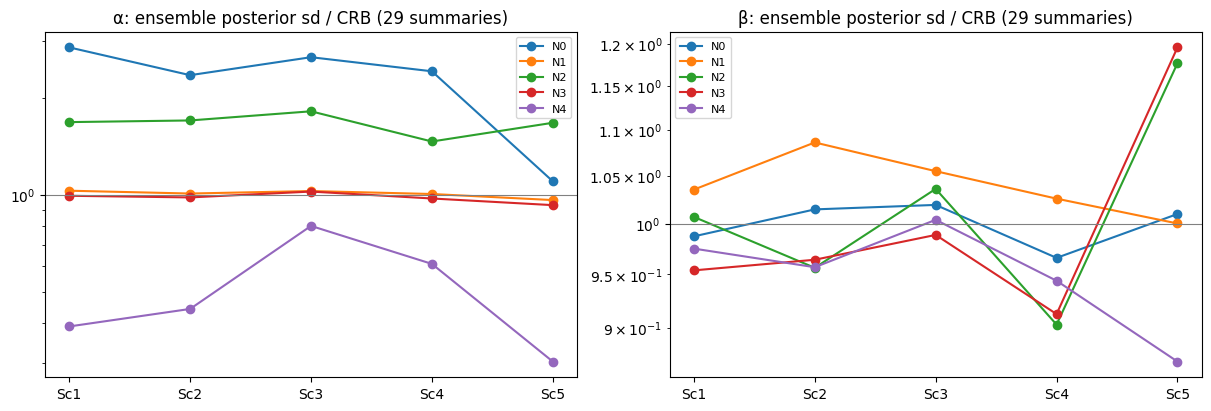

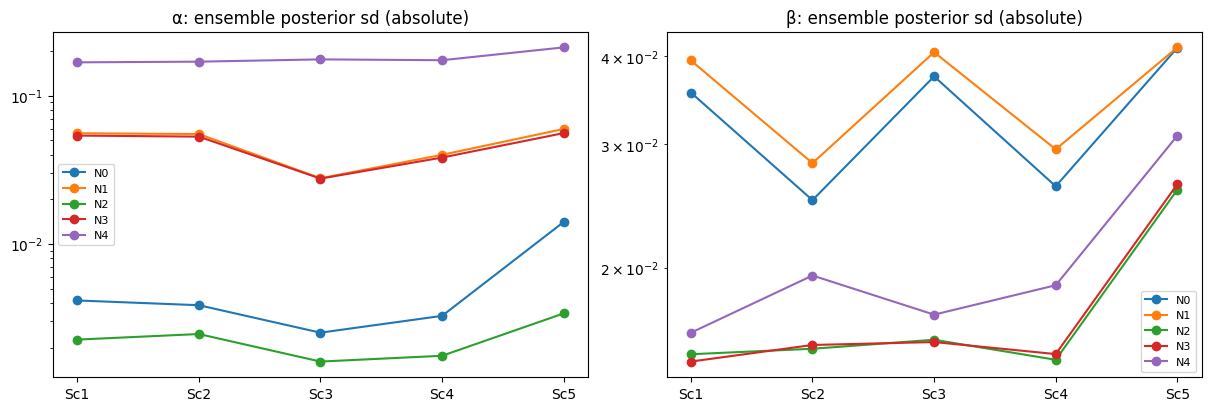

In [7]:
crb = fim[fim.representation == "summaries_fullcov"].set_index(["variant", "point"])
es2 = es.assign(point=es.scenario.str.split("_").str[0])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, par in zip(axes, ("a", "b")):
    for v in N.VARIANTS:
        d = es2[(es2.variant == v) & es2.point.isin(N.GATED)].set_index("point").reindex(N.GATED)
        ratio = [d.loc[p, f"sd_{par}"] / crb.loc[(v, p), f"crb_sd_{par}"] for p in N.GATED]
        ax.plot(N.GATED, ratio, "o-", label=v)
    ax.axhline(1, color="grey", lw=0.8); ax.set_yscale("log")
    ax.set_title(f"{'α' if par == 'a' else 'β'}: ensemble posterior sd / CRB (29 summaries)")
    ax.legend(fontsize=8)
fig.savefig(FIGS / "33_sd_over_crb.png", dpi=150); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, par in zip(axes, ("a", "b")):
    for v in N.VARIANTS:
        d = es2[(es2.variant == v) & es2.point.isin(N.GATED)].set_index("point").reindex(N.GATED)
        ax.plot(N.GATED, d[f"sd_{par}"], "o-", label=v)
    ax.set_yscale("log"); ax.set_title(f"{'α' if par == 'a' else 'β'}: ensemble posterior sd (absolute)")
    ax.legend(fontsize=8)
fig.savefig(FIGS / "33_posterior_sd.png", dpi=150); plt.show()

## 5. Decision (pre-set rule: N3 vs N0 on Sc1–Sc5)

In [8]:
res33 = N.stage_decide()
print("FLAG:", res33["flag"])
print(f"notebook wall time {(time.time() - T0) / 60:.1f} min")

scenario  acc_N0  acc_N3  a_acc_changed  covb_N3  b_cov_outside  corr_N0  corr_N3    regime_N0    regime_N3  c_regime_changed  sd_a_N0  sd_a_N3  sd_b_N0  sd_b_N3
     Sc1    1.00    1.00          False     0.96           True   -0.002    0.045 uncorrelated uncorrelated             False    0.004    0.054    0.036    0.015
     Sc2    0.94    1.00           True     0.94          False    0.049    0.067 uncorrelated uncorrelated             False    0.004    0.053    0.025    0.016
     Sc3    1.00    1.00          False     0.90          False   -0.036    0.052 uncorrelated uncorrelated             False    0.003    0.028    0.037    0.016
     Sc4    1.00    0.88           True     0.96           True    0.021    0.104 uncorrelated uncorrelated             False    0.003    0.038    0.026    0.015
     Sc5    1.00    1.00          False     1.00           True    0.693    0.104     positive uncorrelated              True    0.014    0.056    0.041    0.026
N3 CHANGES A HEADLINE CONCLU

## 6. Interpretation (written 2026-11-09, after the N0–N4 run)

**Decision.** The pre-set rule flagged N3 (it changes headline numbers), and the user adopted
**N3 as the production sensor model on 2026-11-09**. All production notebooks (02, 29, 03 §10b,
31, 07 and Phase 3) are re-run under N3; N0 stays in the SI as the inherited convention.

**What the realistic sensors change (3-seed ensembles at 40k, numbers from §4–5):**

| | N0 (0.5% of max) | N3 (realistic) | why |
|---|---|---|---|
| posterior sd α (Sc1/Sc3/Sc4) | 0.004 / 0.003 / 0.003 | 0.054 / 0.028 / 0.038 | α is read from C at ~98 % conversion; σ_C goes from 9×10⁻⁵ to 0.01 mol/L |
| posterior sd β (Sc1–Sc4) | 0.025–0.037 | ≈ 0.015 | σ_T 1.56 → 0.2 K: the closed-loop T/Tc/Qc balance pins the jacket duty |
| fault class accuracy | 1.0 (Sc2 0.94) | Sc1, Sc2, Sc3, Sc5 1.0; **Sc4 0.88** | Sc4's α = 0.85 is only ~1.3 posterior sd from the 0.90 threshold under N3 |
| macro-F1 (SBC set) | 0.99 | 0.90 | |
| α–β correlation | Sc5 +0.69, others ≈ 0 | all ≈ 0 (Sc5 +0.10) | |

* **Both posteriors sit at their information limit.** The ensemble sd matches the 29-summary
  Cramér–Rao sd to within ~5 % for α and β (α 0.054 vs 0.054 at Sc1; β 0.015 vs 0.015), so the
  N3 precision is set by the sensors, not by the estimator.
* **Where the Sc5 correlation came from.** It survives N1 (realistic C only; +0.22–0.32 in the
  bounds) but disappears in N2 (realistic T only) and N3. The positive α–β ridge under saturation
  was a product of the imprecise temperature measurement of the N0 convention, not of the plant.
  Together with the controller fix, this closes the paper's original α–β correlation question:
  under realistic sensors and a correct PI law, α and β are not confounded anywhere in the catalogue.
* **Calibration at 40k.** N3 ensemble: β interior SBC KS p = 0.41, TARP KS p = 0.81 (pass); α
  interior KS p = 1×10⁻⁴ (fails, as under N0 at this budget). Whether 160k fixes α under N3 is
  tested in `31_budget_convergence_N3.ipynb`.
* **N4 (no usable concentration measurement)**: α becomes unidentifiable (CRB 0.22–0.70, i.e.
  comparable to the prior width), β is unaffected, and classification collapses (Sc1 0.46, Sc2
  0.48, Sc3 0.82, Sc4 0.70, Sc5 0.26; macro-F1 0.54). Practical message for the paper: jacket
  fouling can be diagnosed from temperatures and coolant flow alone; catalyst-activity diagnosis
  needs an online concentration (or conversion) measurement.
* **Caveat found here (affects nb03 §10b and nb29-N3 E2).** Under N2/N3 the raw-trajectory bound
  with Ledoit–Wolf covariance is *looser* than the 29-summary bound for β (0.030 vs 0.015 at Sc1),
  which cannot hold for an exact bound: with precise T the window covariance is strongly
  structured and Ledoit–Wolf shrinkage discards information. Under N3 the summary-based bound is
  the reference for β; the raw-trajectory bound is reported but not used to claim efficiency.

**For the paper.** Main text under N3: β precision ~0.015 (≈ 1.5 % of nominal UA), α precision
0.03–0.06, classification 0.88–1.0 per scenario, no α–β confounding. SI: the N0–N4 ladder as a
sensor-specification study (which measurement buys which diagnosis).

<!-- section7-diagnosis -->
## 7. What the sensor model does to the diagnosis (added 2026-11-09)

Sections 4–6 measured posterior width and calibration. This section asks the operational
question: **does the plant get the right diagnosis?** Three points for the paper:

1. **Classification.** Fault class = the quadrant (threshold 0.90 on α and β) holding most of
   the posterior mass. Per-class F1, macro-F1 (with the spread over the 3 seed members) and
   confusion matrices, on the SBC set (1000 prior draws: every class over the whole prior) and on
   the scenario set (Sc1–Sc7 × 50).
2. **Artefact correlations.** An α–β posterior correlation is a property of the *information the
   sensors deliver*, not of the plant alone: the same Sc5 plant gives a strong ridge under one
   sensor model and none under another, and removing a measurement (N4) or an unmodelled drift
   (Sc7) creates correlations where the plant has none. The SBI correlation is compared with the
   correlation implied by the Fisher information of the same variant (independent of the estimator).
3. **α without a concentration reading (N4).** Catalyst activity enters the measurements almost
   only through C at ~98% conversion; without C the posterior on α should return to the prior,
   while β (read from T, Tc and Qc) is unaffected. Measured as posterior sd / prior sd
   (1 = nothing learned).

Same posteriors (40k × 3 seeds per variant) and test sets as sections 2–4.


In [1]:
import json, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", f"run from notebooks/system_I (cwd {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
import importlib, ws_protocols, ws_eval, ws_metrics, nb29_ws_study, nb33_sensor_noise
for _m in (ws_protocols, ws_eval, ws_metrics, nb29_ws_study, nb33_sensor_noise):
    importlib.reload(_m)
N, wm, we = nb33_sensor_noise, ws_metrics, ws_eval
R7, FIGS7 = ROOT / "results", ROOT / "figures"
V = list(N.VARIANTS)
DESC = {"N0": "N0  0.5% of max (inherited)", "N1": "N1  realistic C only", "N2": "N2  realistic T only",
        "N3": "N3  realistic, all channels", "N4": "N4  realistic, no C reading"}
T0_7 = time.time()
N.stage_classification()
print(f"sampling done in {(time.time() - T0_7) / 60:.1f} min")

N0 0 12s


N0 1 14s


N0 2 10s


N0 ensemble 13s


N1 0 9s


N1 1 8s


... (11 outputs left out)

N4 1 8s


N4 2 8s


N4 ensemble 13s


sampling done in 3.4 min


### 7.1 Classification accuracy and F1 per sensor model
Macro-F1 for the ensemble and mean ± sd over the three seed members; then per-class F1.

In [2]:
f1 = pd.read_csv(R7 / "33_class_f1.csv"); f1["member"] = f1["member"].astype(str)
mac = f1.drop_duplicates(["variant", "member", "set"])[["variant", "member", "set", "macro_f1", "accuracy"]]
ens = mac[mac.member == "ensemble"].pivot(index="variant", columns="set", values=["macro_f1", "accuracy"]).reindex(V)
seeds = mac[mac.member != "ensemble"].groupby(["variant", "set"]).macro_f1.agg(["mean", "std"]).unstack("set").reindex(V)
display(ens.round(3)); display(seeds.round(3))
per_cls = f1[f1.member == "ensemble"].pivot_table(index=["set", "cls"], columns="variant", values="f1")[V]
display(per_cls.round(3))
rec = f1[f1.member == "ensemble"].pivot_table(index=["set", "cls"], columns="variant", values="recall")[V]
print("recall (fraction of each true class recovered):"); display(rec.round(3))

macro_f1           accuracy          
set          sbc scenarios      sbc scenarios
variant                                      
N0         0.968     0.990    0.967     0.990
N1         0.914     0.945    0.921     0.947
N2         0.983     0.867    0.982     0.833
N3         0.932     0.897    0.938     0.883
N4         0.702     0.555    0.720     0.530

mean              std          
set        sbc scenarios    sbc scenarios
variant                                  
N0       0.967     0.987  0.002     0.007
N1       0.912     0.934  0.005     0.008
N2       0.984     0.867  0.002     0.000
N3       0.929     0.900  0.006     0.020
N4       0.688     0.530  0.018     0.051

variant                        N0     N1     N2     N3     N4
set       cls                                                
sbc       combined          0.967  0.935  0.982  0.950  0.758
          decay_dominant    0.954  0.909  0.973  0.936  0.829
          fouling_dominant  0.976  0.928  0.989  0.935  0.539
          healthy           0.975  0.884  0.987  0.908  0.684
scenarios combined          1.000  0.871  0.667  0.715  0.402
          decay_dominant    1.000  0.990  1.000  1.000  0.707
          fouling_dominant  0.990  0.949  0.800  0.874  0.516
          healthy           0.971  0.971  1.000  1.000  0.595

recall (fraction of each true class recovered):


variant                        N0     N1     N2     N3     N4
set       cls                                                
sbc       combined          0.973  0.929  0.978  0.936  0.794
          decay_dominant    0.946  0.900  0.979  0.938  0.838
          fouling_dominant  0.970  0.940  0.991  0.957  0.489
          healthy           0.983  0.899  0.983  0.908  0.681
scenarios combined          1.000  0.880  1.000  0.880  0.720
          decay_dominant    1.000  0.980  1.000  1.000  0.820
          fouling_dominant  0.980  0.940  0.667  0.807  0.380
          healthy           1.000  1.000  1.000  1.000  0.500

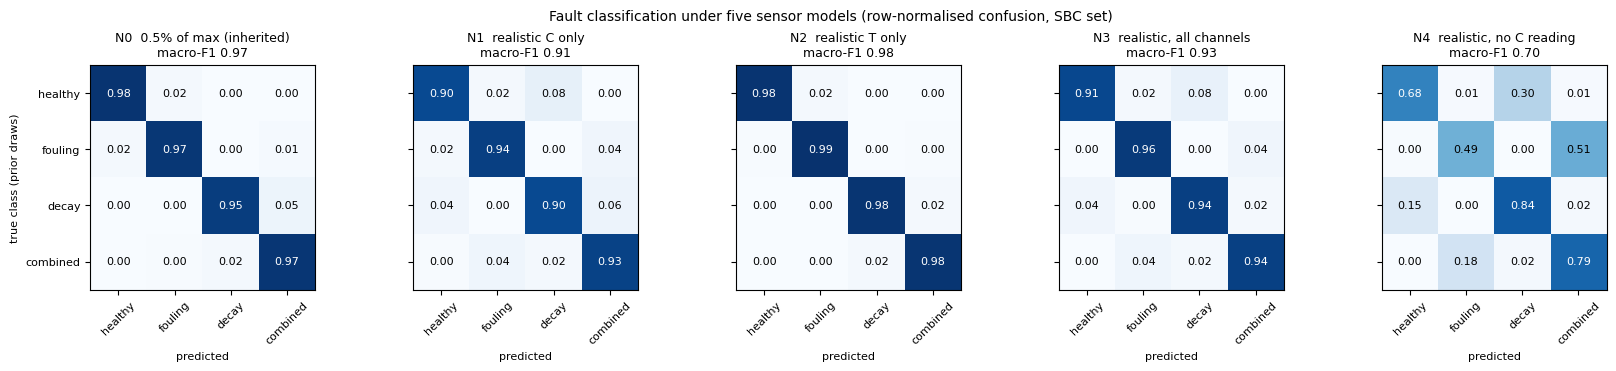

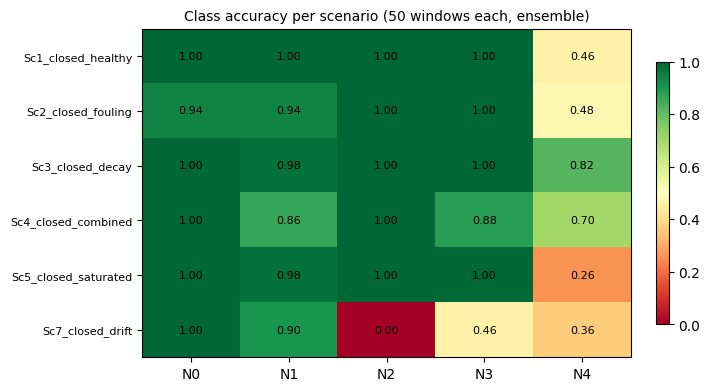

In [3]:
cm = pd.read_csv(R7 / "33_confusion.csv")
C = list(wm.CLASSES); short = ["healthy", "fouling", "decay", "combined"]
fig, axes = plt.subplots(1, len(V), figsize=(3.3 * len(V), 3.6), constrained_layout=True)
for ax, v in zip(axes, V):
    m = cm[(cm.variant == v) & (cm.set == "sbc")].pivot(index="true", columns="pred", values="n").reindex(index=C, columns=C)
    frac = m.div(m.sum(1), axis=0).values
    ax.imshow(frac, vmin=0, vmax=1, cmap="Blues")
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{frac[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if frac[i, j] > 0.6 else "black")
    ax.set_xticks(range(4), short, rotation=45, fontsize=8); ax.set_yticks(range(4), short if v == V[0] else [], fontsize=8)
    mf = ens.loc[v, ("macro_f1", "sbc")]
    ax.set_title(f"{DESC[v]}\nmacro-F1 {mf:.2f}", fontsize=9)
    ax.set_xlabel("predicted", fontsize=8)
axes[0].set_ylabel("true class (prior draws)", fontsize=8)
fig.suptitle("Fault classification under five sensor models (row-normalised confusion, SBC set)", fontsize=10)
fig.savefig(FIGS7 / "33_confusion_by_sensor_model.png", dpi=150); plt.show()

sc = pd.read_csv(R7 / "33_scenarios.csv"); sc["member"] = sc["member"].astype(str)
acc = sc[sc.member == "ensemble"].pivot_table(index="scenario", columns="variant", values="class_acc")[V]
fig, ax = plt.subplots(figsize=(7, 3.8), constrained_layout=True)
im = ax.imshow(acc.values, vmin=0, vmax=1, cmap="RdYlGn", aspect="auto")
for i in range(acc.shape[0]):
    for j in range(acc.shape[1]):
        ax.text(j, i, f"{acc.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(len(V)), V); ax.set_yticks(range(len(acc)), acc.index, fontsize=8)
ax.set_title("Class accuracy per scenario (50 windows each, ensemble)", fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(FIGS7 / "33_accuracy_by_scenario.png", dpi=150); plt.show()

### 7.2 Artefact correlations: the α–β ridge depends on the sensors
Mean posterior Corr(α, β) per scenario (SBI ensemble) next to the correlation implied by the
Fisher information of the same variant (29 summaries, full covariance). Agreement between the
two means the correlation is in the data the sensors deliver, not created by the estimator.
Below: the joint posterior of the same Sc5 window (first replicate) under each sensor model.

SBI posterior Corr(alpha, beta), ensemble mean over windows:


variant,N0,N1,N2,N3,N4
scenario,,,,,
Sc1_closed_healthy,-0.00,0.10,0.08,0.04,0.18
Sc2_closed_fouling,0.05,0.11,0.06,0.07,0.43
Sc3_closed_decay,-0.04,0.08,0.07,0.05,0.23
Sc4_closed_combined,0.02,0.10,0.08,0.10,0.42
Sc5_closed_saturated,0.69,0.20,0.15,0.10,0.52
Sc7_closed_drift,0.64,0.20,0.16,0.12,0.04


Fisher-information implied correlation (29 summaries):


variant,N0,N1,N2,N3,N4
point,,,,,
Sc1,-0.07,0.02,0.04,0.05,0.37
Sc2,-0.04,0.08,-0.00,0.09,0.61
Sc3,-0.08,0.01,0.04,0.05,0.37
Sc4,-0.01,0.05,0.02,0.08,0.57
Sc5,0.76,0.22,0.07,0.04,0.78


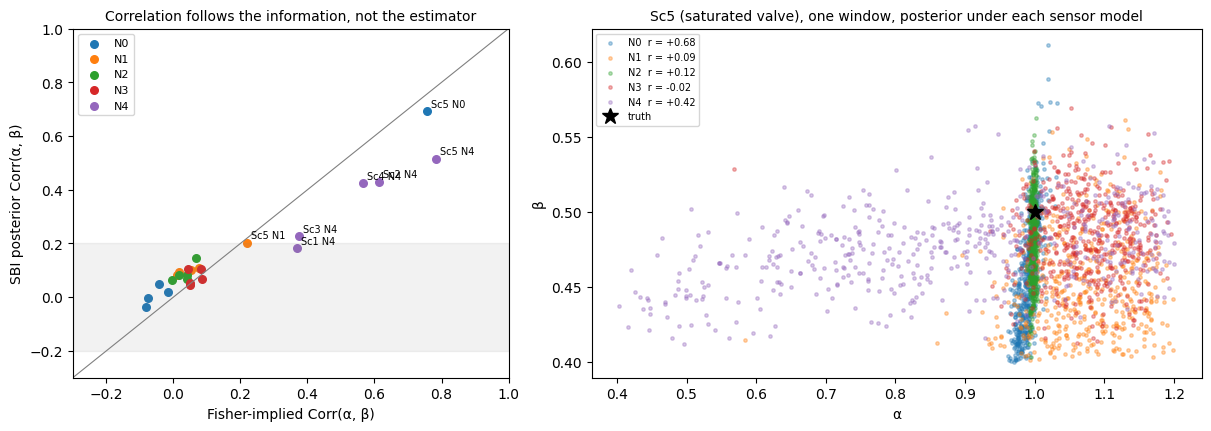

In [4]:
inf = pd.read_csv(R7 / "33_information.csv")
corr_sbi = sc[sc.member == "ensemble"].pivot_table(index="scenario", columns="variant", values="corr_ab_mean")[V]
fim = pd.read_csv(R7 / "33_fim.csv")
corr_fim = fim[fim.representation == "summaries_fullcov"].pivot_table(index="point", columns="variant", values="corr_implied")[V]
print("SBI posterior Corr(alpha, beta), ensemble mean over windows:"); display(corr_sbi.round(2))
print("Fisher-information implied correlation (29 summaries):"); display(corr_fim.round(2))
pts = [(corr_fim.loc[p, v], corr_sbi.loc[[s for s in corr_sbi.index if s.startswith(p + "_")][0], v], v, p)
       for v in V for p in corr_fim.index]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True, gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
for v in V:
    q = [(a, b) for a, b, vv, _ in pts if vv == v]
    ax.scatter(*zip(*q), label=v, s=30)
for a, b, v, p in pts:
    if abs(b) > 0.2 or abs(a) > 0.2:
        ax.annotate(f"{p} {v}", (a, b), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.plot([-1, 1], [-1, 1], color="grey", lw=0.8); ax.axhspan(-0.2, 0.2, color="grey", alpha=0.1)
ax.set_xlim(-0.3, 1); ax.set_ylim(-0.3, 1)
ax.set_xlabel("Fisher-implied Corr(α, β)"); ax.set_ylabel("SBI posterior Corr(α, β)"); ax.legend(fontsize=8)
ax.set_title("Correlation follows the information, not the estimator", fontsize=10)
ax = axes[1]
sc5 = None
for k, v in enumerate(V):
    d = we.load_npz(N.OUT / f"cls_samples_{v}.npz")
    i = int(np.flatnonzero(d["sc_name"] == [s for s in set(d["sc_name"].tolist()) if s.startswith("Sc5_")][0])[0])
    s5 = d["samples"][i]; sc5 = d["theta"][i]
    ax.scatter(s5[:, 0], s5[:, 1], s=6, alpha=0.35, label=f"{v}  r = {np.corrcoef(s5.T)[0, 1]:+.2f}")
ax.plot(*sc5, "k*", ms=12, label="truth")
ax.set_xlabel("α"); ax.set_ylabel("β"); ax.legend(fontsize=7)
ax.set_title("Sc5 (saturated valve), one window, posterior under each sensor model", fontsize=10)
fig.savefig(FIGS7 / "33_artefact_correlation.png", dpi=150); plt.show()

### 7.3 α without a concentration reading
Posterior sd divided by the prior sd (uniform prior on [0.4, 1.2]: sd 0.231); median over
windows. 1 means the data carry no information on that parameter. Below: pooled α and β
marginals for Sc1 (healthy, α = 1) and Sc3 (catalyst decay, α = 0.7) with and without C (N3 vs
N4), and for Sc1 vs Sc2 (fouling, β = 0.85).

sd_ratio_a                             sd_ratio_b         \
variant                      N0     N1     N2     N3     N4         N0     N1   
group                                                                           
SBC (prior draws)         0.016  0.150  0.008  0.147  0.820      0.155  0.166   
Sc1_closed_healthy        0.012  0.246  0.008  0.237  0.760      0.153  0.169   
Sc2_closed_fouling        0.013  0.241  0.009  0.232  0.734      0.105  0.120   
Sc3_closed_decay          0.007  0.121  0.005  0.117  0.780      0.162  0.175   
Sc4_closed_combined       0.010  0.167  0.006  0.164  0.747      0.113  0.127   
Sc5_closed_saturated      0.058  0.265  0.012  0.244  0.913      0.179  0.180   
Sc7_closed_drift          0.037  0.304  0.033  0.325  0.667      0.271  0.295   

                                           
variant                  N2     N3     N4  
group                                      
SBC (prior draws)     0.085  0.085  0.103  
Sc1_closed_healthy    0.064  0.063  0.069  
Sc2_closed_fouling    0.065  0.065  0.082  
Sc3_closed_decay      0.066  0.067  0.072  
Sc4_closed_combined   0.061  0.065  0.078  
Sc5_closed_saturated  0.111  0.112  0.133  
Sc7_closed_drift      0.070  0.092  0.100

Cramér–Rao sd of alpha (29 summaries); the prior sd is 0.231:


variant,N0,N1,N2,N3,N4
point,,,,,
Sc1,0.001,0.054,0.001,0.054,0.430
Sc2,0.002,0.055,0.001,0.054,0.383
Sc3,0.001,0.027,0.001,0.027,0.219
Sc4,0.001,0.040,0.001,0.039,0.284
Sc5,0.013,0.062,0.002,0.060,0.697


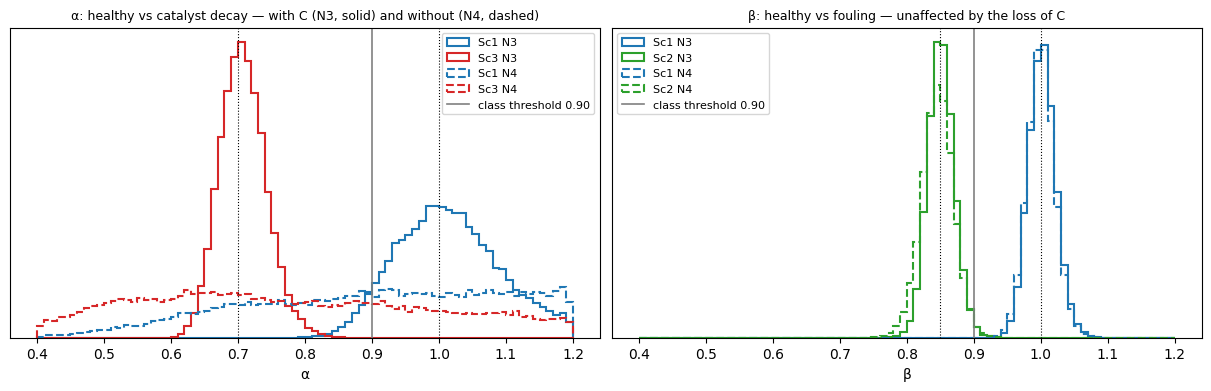

section 7 wall time 3.4 min


In [5]:
ratio = inf.pivot_table(index="group", columns="variant", values=["sd_ratio_a", "sd_ratio_b"])
display(ratio.round(3))
crb = fim[fim.representation == "summaries_fullcov"].pivot_table(index="point", columns="variant", values="crb_sd_a")[V]
print("Cramér–Rao sd of alpha (29 summaries); the prior sd is 0.231:"); display(crb.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
bins = np.linspace(0.4, 1.2, 81)
for v, ls in (("N3", "-"), ("N4", "--")):
    d = we.load_npz(N.OUT / f"cls_samples_{v}.npz")
    for pre, col in (("Sc1_", "C0"), ("Sc3_", "C3"), ("Sc2_", "C2")):
        m = np.char.startswith(d["sc_name"].astype(str), pre)
        if pre != "Sc2_":
            axes[0].hist(d["samples"][m][:, :, 0].ravel(), bins=bins, density=True, histtype="step", color=col, ls=ls,
                         lw=1.5, label=f"{pre[:-1]} {v}")
        if pre != "Sc3_":
            axes[1].hist(d["samples"][m][:, :, 1].ravel(), bins=bins, density=True, histtype="step", color=col, ls=ls,
                         lw=1.5, label=f"{pre[:-1]} {v}")
for ax, name, truths in ((axes[0], "α", (1.0, 0.7)), (axes[1], "β", (1.0, 0.85))):
    for t_ in truths:
        ax.axvline(t_, color="k", lw=0.8, ls=":")
    ax.axvline(0.90, color="grey", lw=1.2, label="class threshold 0.90")
    ax.set_xlabel(name); ax.legend(fontsize=8); ax.set_yticks([])
axes[0].set_title("α: healthy vs catalyst decay — with C (N3, solid) and without (N4, dashed)", fontsize=9)
axes[1].set_title("β: healthy vs fouling — unaffected by the loss of C", fontsize=9)
fig.savefig(FIGS7 / "33_alpha_without_C.png", dpi=150); plt.show()
print(f"section 7 wall time {(time.time() - T0_7) / 60:.1f} min")

### 7.4 Interpretation — written 2026-11-09 (N3 production run)

**1. Classification: under the production sensor model N3 the diagnosis is good but not near-perfect, and the errors sit where only α separates the classes.**
Macro-F1 on 1000 prior draws is 0.929 ± 0.006 over the three seeds (ensemble 0.932); on the scenario set (Sc1–Sc7 × 50) it is 0.900 ± 0.020 (ensemble 0.897). The inherited sensor model N0 gave 0.967 ± 0.002 and 0.987 ± 0.007, so N0 overstated the diagnosis by about 4 points on prior draws and 9 on the scenarios. The N3 confusion matrix puts the errors in the α-only pairs: healthy → decay 0.08, decay → healthy 0.04, combined ↔ fouling 0.04 each way; fouling and healthy are rarely confused (0.00–0.02), because β is read sharply (posterior sd 0.065–0.11 of the prior sd). By scenario (N3): Sc1, Sc2, Sc3, Sc5 accuracy 1.00; **Sc4 0.88**, which is what the α precision predicts (α = 0.85 lies 0.05 below the 0.90 threshold, about 1.3 posterior sd for an α sd of ≈ 0.04, so ≈ 0.90 correct). Classification accuracy follows the precision of the C reading: the two models with σ_C ≈ 10⁻⁴ mol/L (N0, N2) reach 0.97–0.98, the two with σ_C = 0.01 mol/L (N1, N3) 0.91–0.93, and N4 without C 0.69 ± 0.02. **One scenario fails under N3: Sc7 (mild fouling + 2 K sensor drift), accuracy 0.46 (N0 1.00, N1 0.90, N2 0.00).** Only the models with a precise T sensor (N2, N3) misread it, so the T precision, not the C precision, is what turns the unmodelled drift into a misdiagnosis; the mechanism beyond that is not tested here.
*Claims.* Supports claim 1 and claim 2 for β and for the faults that change β or α by more than about 0.1; weakens any statement that the closed-loop diagnosis is ~99% accurate (that was a property of the N0 sensor model) and shows that robustness to sensor drift has to be demonstrated separately (notebook 09, Phase 3). These are 40k-simulation, three-seed posteriors; the production figures come from notebook 31.

**2. Artefact correlations: they follow the information the sensors deliver, and under N3 none is left.**
(a) *Sc5 ridge.* Mean SBI Corr(α, β): N0 +0.67 ± 0.04 (members +0.62, +0.69, +0.70; Fisher-implied +0.76), N1 +0.20, N2 +0.15, **N3 +0.10 ± 0.03** (Fisher +0.04). The ridge is produced by the imprecise T reading (σ ≈ 1.6 K in N0), not by the plant. (b) *Loss of C (N4).* A correlation appears in every closed-loop scenario: SBI +0.15 ± 0.03 (Sc1), +0.36 ± 0.04 (Sc4), +0.51 ± 0.07 (Sc5), against Fisher-implied +0.37, +0.57, +0.78. The SBI value has the same sign and order as the Fisher value but is lower by 0.1–0.3; I attribute this to the prior truncating the broad α posterior at [0.4, 1.2], which a local Gaussian bound does not know about, but I have not tested that. (c) *Sc7 drift.* N0 +0.52 ± 0.10 (members +0.44 to +0.63), N3 +0.09 ± 0.07, N4 −0.04 ± 0.13: this correlation is a consequence of the unmodelled drift under the imprecise sensors, and there is no Fisher counterpart to compare with (the drift is not in the model), so it is misspecification, not information. Under N3 every plant scenario has a mean correlation between 0.04 and 0.12 (Fisher 0.04–0.09).
*Claims.* Supports claim 3 for the sensor model: the strong α–β correlation seen under N0 is a property of the measurement set-up. This notebook establishes only the sensor-model part; the controller form and the noise-free start (notebook 29) are the other two causes in the ledger.

**3. Without a concentration reading α is weakly, not un-, identified, and the result is more nuanced than "returns to the prior".**
The α posterior sd / prior sd under N4 is 0.67–0.91 by scenario (0.82 on prior draws; Cramér–Rao sd 0.22–0.70 against a prior sd of 0.231), against 0.12–0.33 under N3. α keeps some information (through the heat balance in T, Tc and Qc) but its posterior is far wider than the 0.10 class margin. Healthy (α = 1) and catalyst-decay (α = 0.7) plants overlap strongly (Sc1 vs Sc3 marginals in the figure) but are **not indistinguishable**: decay is recognised in 0.82 of the Sc3 windows, healthy in only 0.46 of the Sc1 windows, with 0.30 of healthy prior draws called decay. β is essentially unaffected: sd ratio 0.085 (N3) → 0.103 (N4) on prior draws, 0.065–0.11 → 0.069–0.13 by scenario, and the Sc1 vs Sc2 β marginals coincide. **But the fouling *class* does not survive:** fouling recall falls from 0.96 to 0.49 (0.51 of fouling draws are called combined) because the class boundary depends on α. The parameter β survives the loss of C; the four-class label does not.
*Claims.* Weakens the runbook's expected statement ("α returns to the prior, healthy and decay indistinguishable"); the data support "α weakly identified, β unaffected".

**4. Practical statement for the paper.**
β (and the jacket-fouling diagnosis) comes from T, Tc and Qc and is robust to the sensor model (sd ratio 0.065–0.13 in all models). α, and with it the healthy / decay / combined labels, requires a C reading, and its precision sets the accuracy: σ_C = 0.01 mol/L gives macro-F1 ≈ 0.93 (prior draws) and ≈ 0.90 (scenarios), no reading gives ≈ 0.69. A precise T sensor (0.2 K) removes the Sc5 α–β ridge and makes the posterior sensitive to unmodelled T drift, so the drift has to be modelled or detected (notebook 09, MMD test in nb29 E5).
